In [1]:
# import libraries for optimization, preprocessing and evaluation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import optuna
import time

from sklearn.model_selection import train_test_split, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [2]:
# load pharmacy sales dataset

df = pd.read_csv("global_pharmacy_sales_data.csv")

print("dataset shape:", df.shape)

display(df.head())

dataset shape: (177990, 14)


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [3]:
# clean dataset and separate features and target

df = df.drop_duplicates()

df = df.drop(columns=["date"], errors="ignore")

df = df.dropna(subset=["units_sold"])

X = df.drop(columns=["units_sold"])
y = df["units_sold"]

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("numerical features:", numeric_features)
print("categorical features:", categorical_features)

print("target variable: units_sold")

numerical features: ['year', 'month', 'day', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
categorical features: ['region', 'country', 'category', 'medicine', 'age_group']
target variable: units_sold


In [4]:
# split data into training and independent testing datasets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# create a smaller sample to reduce optimization time

tuning_size = min(6000, len(X_train))
evaluation_size = min(5000, len(X_test))

X_tuning = X_train.sample(
    n=tuning_size,
    random_state=42
)

y_tuning = y_train.loc[X_tuning.index]

X_evaluation = X_test.sample(
    n=evaluation_size,
    random_state=42
)

y_evaluation = y_test.loc[X_evaluation.index]

print("tuning records:", len(X_tuning))
print("evaluation records:", len(X_evaluation))

tuning records: 6000
evaluation records: 5000


In [5]:
# prepare numerical and categorical features

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("feature preprocessing completed")

feature preprocessing completed


In [6]:
# configure cross-validation to evaluate model performance

cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

print("cross-validation folds:", cv.n_splits)

cross-validation folds: 3


In [7]:
# define optuna objective with tpe sampling and cross-validation pruning

def objective(trial):

    # select hyperparameters automatically

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 30, 80, step=10
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 5, 25
        ),

        "min_samples_split": trial.suggest_int(
            "min_samples_split", 2, 20
        ),

        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf", 1, 10
        ),

        "max_features": trial.suggest_categorical(
            "max_features", ["sqrt", 0.8, 1.0]
        ),

        "bootstrap": trial.suggest_categorical(
            "bootstrap", [True, False]
        ),

        "max_leaf_nodes": trial.suggest_int(
            "max_leaf_nodes", 20, 100
        ),

        "ccp_alpha": trial.suggest_float(
            "ccp_alpha", 0.0, 0.02
        )
    }

    fold_scores = []

    # evaluate parameters using cross-validation

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_tuning)
    ):

        X_fold_train = X_tuning.iloc[train_idx]
        X_fold_val = X_tuning.iloc[val_idx]

        y_fold_train = y_tuning.iloc[train_idx]
        y_fold_val = y_tuning.iloc[val_idx]

        # create preprocessing and model pipeline

        pipeline = Pipeline([
            ("preprocessor", preprocessor),

            ("model", RandomForestRegressor(
                **params,
                random_state=42,
                n_jobs=1
            ))
        ])

        # train model on current fold

        pipeline.fit(X_fold_train, y_fold_train)

        # calculate validation rmse

        predictions = pipeline.predict(X_fold_val)

        fold_rmse = np.sqrt(
            mean_squared_error(y_fold_val, predictions)
        )

        fold_scores.append(fold_rmse)

        # report intermediate performance to optuna

        trial.report(
            np.mean(fold_scores),
            step=fold
        )

        # stop unpromising trials early

        if trial.should_prune():
            raise optuna.TrialPruned()

    # return average cross-validation rmse

    return np.mean(fold_scores)

In [8]:
# configure tpe sampler and median pruning strategy

sampler = optuna.samplers.TPESampler(
    seed=42,
    n_startup_trials=4,
    multivariate=True
)

pruner = optuna.pruners.MedianPruner(
    n_startup_trials=4,
    n_warmup_steps=1
)

study = optuna.create_study(
    direction="minimize",
    sampler=sampler,
    pruner=pruner
)

print("tpe search algorithm configured")
print("median pruning configured")

[I 2026-11-01 18:24:40,604] A new study created in memory with name: no-name-50c8d8cb-12c4-4787-a127-db2941673994


tpe search algorithm configured
median pruning configured


In [10]:
# execute optuna hyperparameter optimization under a limited trial budget

start_time = time.time()

study.optimize(
    objective,
    n_trials=12,
    n_jobs=1,
    show_progress_bar=True
)

optimization_time = time.time() - start_time

print("\noptimization completed")

print("execution time:",
      round(optimization_time, 2), "seconds")

print("completed trials:",
      len(study.trials))

print("pruned trials:",
      sum(t.state == optuna.trial.TrialState.PRUNED
          for t in study.trials))

  0%|          | 0/12 [00:00<?, ?it/s]

[I 2026-11-01 18:25:18,963] Trial 0 finished with value: 203.59112434621807 and parameters: {'n_estimators': 50, 'max_depth': 24, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_features': 'sqrt', 'bootstrap': True, 'max_leaf_nodes': 77, 'ccp_alpha': 0.00041168988591604893}. Best is trial 0 with value: 203.59112434621807.
[I 2026-11-01 18:25:26,206] Trial 1 finished with value: 87.73339272465883 and parameters: {'n_estimators': 80, 'max_depth': 22, 'min_samples_split': 6, 'min_samples_leaf': 2, 'max_features': 1.0, 'bootstrap': True, 'max_leaf_nodes': 69, 'ccp_alpha': 0.0027898772130408368}. Best is trial 1 with value: 87.73339272465883.
[I 2026-11-01 18:25:29,044] Trial 2 finished with value: 100.30017322588094 and parameters: {'n_estimators': 40, 'max_depth': 12, 'min_samples_split': 10, 'min_samples_leaf': 8, 'max_features': 1.0, 'bootstrap': False, 'max_leaf_nodes': 33, 'ccp_alpha': 0.0013010318597055904}. Best is trial 1 with value: 87.73339272465883.
[I 2026-11-01 18:25:32,9

In [11]:
# extract the best parameters and validation performance

best_params = study.best_params

best_cv_rmse = study.best_value

print("best hyperparameters:")

for parameter, value in best_params.items():
    print(parameter, ":", value)

print("\nbest cross-validation rmse:",
      round(best_cv_rmse, 4))

best hyperparameters:
n_estimators : 80
max_depth : 22
min_samples_split : 6
min_samples_leaf : 2
max_features : 1.0
bootstrap : True
max_leaf_nodes : 69
ccp_alpha : 0.0027898772130408368

best cross-validation rmse: 87.7334


In [12]:
# train the best optimized model using the complete tuning sample

final_model = Pipeline([
    ("preprocessor", preprocessor),

    ("model", RandomForestRegressor(
        **best_params,
        random_state=42,
        n_jobs=1
    ))
])

final_start = time.time()

final_model.fit(X_tuning, y_tuning)

final_fit_time = time.time() - final_start

print("optimized model training completed")

print("training time:",
      round(final_fit_time, 2), "seconds")

optimized model training completed
training time: 3.46 seconds


In [13]:
# evaluate optimized model on independent testing records

y_pred = final_model.predict(X_evaluation)

mae = mean_absolute_error(
    y_evaluation, y_pred
)

rmse = np.sqrt(
    mean_squared_error(y_evaluation, y_pred)
)

r2 = r2_score(
    y_evaluation, y_pred
)

# calculate training performance to inspect overfitting

train_pred = final_model.predict(X_tuning)

train_rmse = np.sqrt(
    mean_squared_error(y_tuning, train_pred)
)

# calculate generalization gap

overfitting_gap = rmse - train_rmse

evaluation_results = pd.DataFrame({
    "Metric": [
        "Training RMSE",
        "Testing RMSE",
        "MAE",
        "R-Squared",
        "Generalization Gap"
    ],

    "Score": [
        train_rmse,
        rmse,
        mae,
        r2,
        overfitting_gap
    ]
})

display(evaluation_results)

,Metric,Score
0,Training RMSE,76.842883
1,Testing RMSE,91.224386
2,MAE,66.581440
3,R-Squared,0.934080
4,Generalization Gap,14.381503


In [14]:
# compare training and testing performance to identify possible overfitting

print("training rmse:", round(train_rmse, 4))

print("testing rmse:", round(rmse, 4))

print("generalization gap:", round(overfitting_gap, 4))

if overfitting_gap > 0:
    print("\ntraining error is lower than testing error")

elif overfitting_gap < 0:
    print("\ntesting error is lower than training error")

else:
    print("\ntraining and testing errors are equal")

print("\nuse the validation and test results together to assess generalization")

training rmse: 76.8429
testing rmse: 91.2244
generalization gap: 14.3815

training error is lower than testing error

use the validation and test results together to assess generalization


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_4700\3884915401.py:3: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_optimization_history(


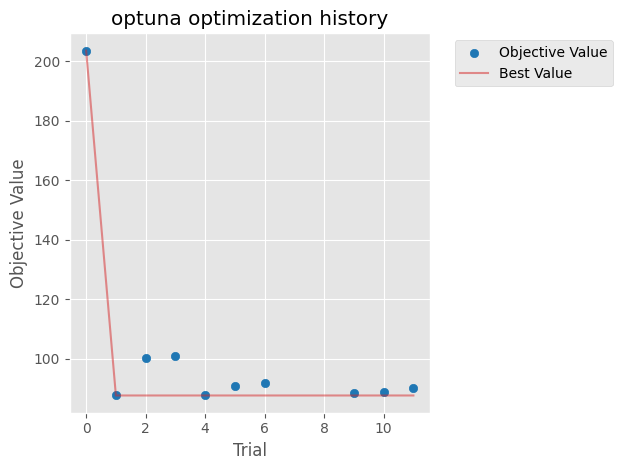

In [15]:
# visualize how optuna improves the best validation score across trials

optuna.visualization.matplotlib.plot_optimization_history(
    study
)

plt.title("optuna optimization history")

plt.tight_layout()

plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_4700\3969621596.py:3: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(


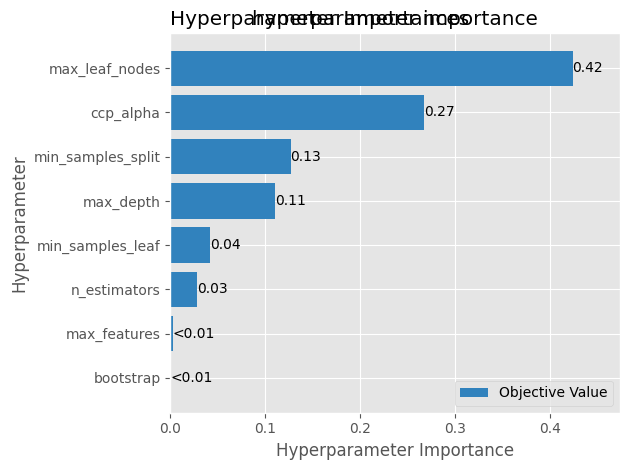

In [16]:
# identify the most influential hyperparameters

optuna.visualization.matplotlib.plot_param_importances(
    study
)

plt.title("hyperparameter importance")

plt.tight_layout()

plt.show()

In [17]:
# display trial parameters and their validation performance

trial_results = study.trials_dataframe(
    attrs=("number", "value", "state", "params")
)

display(trial_results)

,number,value,state,params_bootstrap,params_ccp_alpha,params_max_depth,params_max_features,params_max_leaf_nodes,params_min_samples_leaf,params_min_samples_split,params_n_estimators
0,0,203.591124,COMPLETE,True,0.000412,24,sqrt,77,6,15,50
1,1,87.733393,COMPLETE,True,0.002790,22,1.0,69,2,6,80
2,2,100.300173,COMPLETE,False,0.001301,12,1.0,33,8,10,40
3,3,100.884345,COMPLETE,False,0.018186,25,0.8,22,4,17,80
4,4,87.799018,COMPLETE,True,0.000098,17,1.0,85,3,2,80
5,5,90.905915,COMPLETE,True,0.010780,16,1.0,60,1,16,30
6,6,91.946008,COMPLETE,True,0.017597,22,1.0,90,5,5,60
7,7,100.732888,PRUNED,True,0.008198,5,1.0,60,2,18,70
8,8,115.662852,PRUNED,True,0.012085,11,1.0,59,10,2,40
9,9,88.432940,COMPLETE,True,0.002268,24,1.0,100,1,10,70


In [19]:
# display final optuna optimization and model evaluation summary

completed_trials = sum(
    t.state == optuna.trial.TrialState.COMPLETE
    for t in study.trials
)

pruned_trials = sum(
    t.state == optuna.trial.TrialState.PRUNED
    for t in study.trials
)



print("optimization algorithm: tpe sampler")
print("pruning strategy: median pruner")
print("total trials:", len(study.trials))
print("completed trials:", completed_trials)
print("pruned trials:", pruned_trials)
print("search dimensions:", len(best_params))
print("cross-validation folds:", cv.n_splits)
print("best cv rmse:", round(best_cv_rmse, 4))
print("optimization time:", round(optimization_time, 2))


print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 score:", round(r2, 4))
print("training RMSE:", round(train_rmse, 4))
print("generalization gap:", round(overfitting_gap, 4))
print("\noptuna hyperparameter optimization completed")

optimization algorithm: tpe sampler
pruning strategy: median pruner
total trials: 12
completed trials: 10
pruned trials: 2
search dimensions: 8
cross-validation folds: 3
best cv rmse: 87.7334
optimization time: 54.58
MAE: 66.5814
RMSE: 91.2244
R2 score: 0.9341
training RMSE: 76.8429
generalization gap: 14.3815

optuna hyperparameter optimization completed
